# RQ2扩展：四个冠军模型在不同海洋区域的表现

本Notebook不重新选择模型，也不使用test set调参。它把已经在training partition上选好的四个冠军模型，放到完全相同的757个held-out test cases中，并按 **Shelf、Kuroshio Core、Transition、Other Offshore** 分组比较。

冠军模型：Optimised FNN、Boosting residual、Optimised Weighted KNN、Optimised Random Forest。两条物理baseline同时保留作参照。

主要回答：

1. 冠军模型在不同regime中是否仍保持优势？
2. 哪个模型的72小时median error、RMSE、ITE和尾部风险最好？
3. Kuroshio Core中的排序是否改变？

> 这里分析的是固定全区域模型在不同区域上的泛化。它不是“用每个区域重新训练一个模型”的regional retraining实验。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p/'data'/'processed').exists()), None)
if PROJECT is None:
    raise FileNotFoundError('请从data3001-project或其子目录运行。')

RQ2 = PROJECT/'RQ2'
OUT = RQ2/'champion_models'/'output'
OUT.mkdir(parents=True, exist_ok=True)
ZH = PROJECT/'output'/'rq1'/'zh'
EN = PROJECT/'output'/'rq1'/'en'

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['PingFang SC','Arial Unicode MS','DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('项目目录：', PROJECT)
print('输出目录：', OUT)

项目目录： /Users/roger/Documents/data3001-project
输出目录： /Users/roger/Documents/data3001-project/RQ2/champion_models/output


## 1. 读取同一批test cases

所有模型必须满足三项公平性条件：case ID完全相同、每个case只出现一次、drifter/regime标签按case ID合并而不是依赖行顺序。

In [2]:
origins = pd.read_parquet(PROJECT/'data'/'processed'/'forecast_origins.parquet')
origins = origins.sort_values('forecast_case_id').reset_index(drop=True)
test_meta = origins.loc[origins.partition.eq('test'), ['forecast_case_id','ID']].copy()

regimes = pd.read_csv(RQ2/'data'/'forecast_case_regimes.csv')[
    ['forecast_case_id','regime','current_speed_clim','distance_to_kuroshio_km','depth_m']
]
test_meta = test_meta.merge(regimes, on='forecast_case_id', how='left', validate='one_to_one')

assert len(test_meta) == 757
assert test_meta.forecast_case_id.is_unique
assert test_meta.regime.notna().all()
assert set(test_meta.regime) == {'Shelf','Kuroshio Core','Transition','Other Offshore'}
display(test_meta.groupby('regime').agg(test_cases=('forecast_case_id','size'),
                                        test_drifters=('ID','nunique')))

,test_cases,test_drifters
regime,,
Kuroshio Core,139,45
Other Offshore,341,41
Shelf,112,28
Transition,165,43


## 2. 统一四个冠军模型与两条baseline的输出格式

每个CSV提供每个test case的72小时终点Haversine误差和72小时ITE。不同Notebook曾使用略有不同的列名，本节只做列名标准化，不修改数值。

In [3]:
MODEL_FILES = {
    'Velocity persistence': EN/'velocity_persistence_test_case_metrics.csv',
    'Spatial mean flow': EN/'spatial_mean_flow_test_case_metrics.csv',
    'Optimised FNN': ZH/'optimised_fnn_test_case_metrics.csv',
    'Boosting residual': ZH/'boosting_residual_test_case_metrics.csv',
    'Optimised Weighted KNN': ZH/'optimised_knn_test_case_metrics.csv',
    'Optimised Random Forest': ZH/'optimised_random_forest_test_case_metrics.csv',
}

def standardise_case_metrics(model, path):
    d = pd.read_csv(path)
    ren = {
        'drifter_id':'ID',
        'error_72h_km':'final_72h_error_km',
        'ite_km_h':'integrated_trajectory_error_km_h',
    }
    d = d.rename(columns=ren)
    required = {'forecast_case_id','final_72h_error_km','integrated_trajectory_error_km_h'}
    missing = required-set(d.columns)
    if missing:
        raise ValueError(f'{model}缺少列：{missing}')
    d = d[['forecast_case_id','final_72h_error_km','integrated_trajectory_error_km_h']].copy()
    assert len(d)==757 and d.forecast_case_id.is_unique
    assert set(d.forecast_case_id)==set(test_meta.forecast_case_id)
    assert np.isfinite(d[['final_72h_error_km','integrated_trajectory_error_km_h']]).all().all()
    d['model'] = model
    return d

errors = pd.concat([standardise_case_metrics(m,p) for m,p in MODEL_FILES.items()], ignore_index=True)
errors = errors.merge(test_meta, on='forecast_case_id', how='left', validate='many_to_one')
assert len(errors)==757*len(MODEL_FILES)
assert errors.groupby('forecast_case_id').model.nunique().eq(len(MODEL_FILES)).all()
print('审计通过：',len(errors),'行；',errors.model.nunique(),'个模型；757个共同test cases。')

审计通过： 4542 行； 6 个模型；757个共同test cases。


## 3. 计算区域指标

- **Median 72-h error**：典型case的终点误差，抗极端值。
- **72-h RMSE**：更强调少数巨大误差，适合关注风险尾部。
- **Median ITE**：整个1–72小时误差曲线的累计面积。
- **Worst-10% RMSE**：每个regime内部最差10% cases的RMSE。

In [4]:
def summarise(g):
    e = g.final_72h_error_km.to_numpy()
    threshold = np.quantile(e,.9)
    return pd.Series({
        'n_cases':len(g), 'n_drifters':g.ID.nunique(),
        'median_72h_km':np.median(e),
        'rmse_72h_km':np.sqrt(np.mean(e**2)),
        'median_ite_km_h':np.median(g.integrated_trajectory_error_km_h),
        'worst10_rmse_72h_km':np.sqrt(np.mean(e[e>=threshold]**2)),
    })

summary = errors.groupby(['regime','model'], observed=True).apply(summarise, include_groups=False).reset_index()
summary.to_csv(OUT/'champion_regime_summary.csv', index=False)
for metric in ['median_72h_km','rmse_72h_km','median_ite_km_h','worst10_rmse_72h_km']:
    display(Markdown('### '+metric))
    display(summary.pivot(index='model',columns='regime',values=metric).round(2))

### median_72h_km

regime,Kuroshio Core,Other Offshore,Shelf,Transition
model,,,,
Boosting residual,58.23,39.92,27.73,44.94
Optimised FNN,61.22,39.51,24.66,43.20
Optimised Random Forest,63.20,40.33,24.34,40.37
Optimised Weighted KNN,62.48,39.08,24.08,40.06
Spatial mean flow,77.10,62.66,30.89,47.14
Velocity persistence,83.32,56.60,46.30,69.74


### rmse_72h_km

regime,Kuroshio Core,Other Offshore,Shelf,Transition
model,,,,
Boosting residual,81.71,53.23,43.57,64.60
Optimised FNN,85.86,52.66,40.83,66.24
Optimised Random Forest,86.25,53.54,40.39,66.60
Optimised Weighted KNN,89.57,54.67,40.11,67.78
Spatial mean flow,105.33,78.44,46.07,81.14
Velocity persistence,120.36,78.56,75.54,91.73


### median_ite_km_h

regime,Kuroshio Core,Other Offshore,Shelf,Transition
model,,,,
Boosting residual,2028.39,1340.57,1022.01,1503.18
Optimised FNN,2087.38,1324.78,978.30,1447.36
Optimised Random Forest,2246.05,1321.58,968.06,1422.97
Optimised Weighted KNN,2281.72,1327.81,1004.47,1427.34
Spatial mean flow,3011.49,2352.42,1173.82,2038.52
Velocity persistence,2570.63,1865.31,1627.32,2257.52


### worst10_rmse_72h_km

regime,Kuroshio Core,Other Offshore,Shelf,Transition
model,,,,
Boosting residual,166.08,102.06,99.94,138.77
Optimised FNN,177.06,104.87,95.17,144.17
Optimised Random Forest,174.64,107.40,92.94,150.25
Optimised Weighted KNN,180.23,112.74,89.39,154.18
Spatial mean flow,199.24,150.62,94.63,185.42
Velocity persistence,247.54,161.41,171.42,180.59


## 4. Drifter-cluster bootstrap 95%置信区间

同一drifter可以产生多个高度相关的forecast cases，因此不能把所有case当成独立样本。下面以完整drifter为单位重抽样，估计每个模型在每个regime中的median和RMSE区间。

In [5]:
def cluster_bootstrap(frame, n_boot=2000, seed=2026):
    rng = np.random.default_rng(seed)
    rows=[]
    for (regime,model),g in frame.groupby(['regime','model'], observed=True):
        groups={k:v.final_72h_error_km.to_numpy() for k,v in g.groupby('ID')}
        ids=np.array(list(groups),dtype=object)
        med=[]; rms=[]
        for _ in range(n_boot):
            sample=np.concatenate([groups[i] for i in rng.choice(ids,len(ids),replace=True)])
            med.append(np.median(sample)); rms.append(np.sqrt(np.mean(sample**2)))
        e=g.final_72h_error_km.to_numpy()
        for metric,point,values in [
            ('median_72h_km',np.median(e),med),
            ('rmse_72h_km',np.sqrt(np.mean(e**2)),rms),
        ]:
            lo,hi=np.quantile(values,[.025,.975])
            rows.append({'regime':regime,'model':model,'metric':metric,'estimate':point,
                         'ci_lower':lo,'ci_upper':hi,'n_drifters':len(ids)})
    return pd.DataFrame(rows)

boot = cluster_bootstrap(errors)
boot.to_csv(OUT/'champion_regime_cluster_bootstrap.csv',index=False)
display(boot.round(2).head(12))

,regime,model,metric,estimate,ci_lower,ci_upper,n_drifters
0,Kuroshio Core,Boosting residual,median_72h_km,58.23,50.80,66.71,45
1,Kuroshio Core,Boosting residual,rmse_72h_km,81.71,71.88,91.95,45
2,Kuroshio Core,Optimised FNN,median_72h_km,61.22,53.84,75.27,45
3,Kuroshio Core,Optimised FNN,rmse_72h_km,85.86,76.36,96.03,45
4,Kuroshio Core,Optimised Random Forest,median_72h_km,63.20,54.86,77.13,45
5,Kuroshio Core,Optimised Random Forest,rmse_72h_km,86.25,76.22,97.29,45
6,Kuroshio Core,Optimised Weighted KNN,median_72h_km,62.48,58.12,76.46,45
7,Kuroshio Core,Optimised Weighted KNN,rmse_72h_km,89.57,79.22,100.16,45
8,Kuroshio Core,Spatial mean flow,median_72h_km,77.10,65.09,92.14,45
9,Kuroshio Core,Spatial mean flow,rmse_72h_km,105.33,95.56,114.38,45


## 5. 可视化：冠军模型与baseline

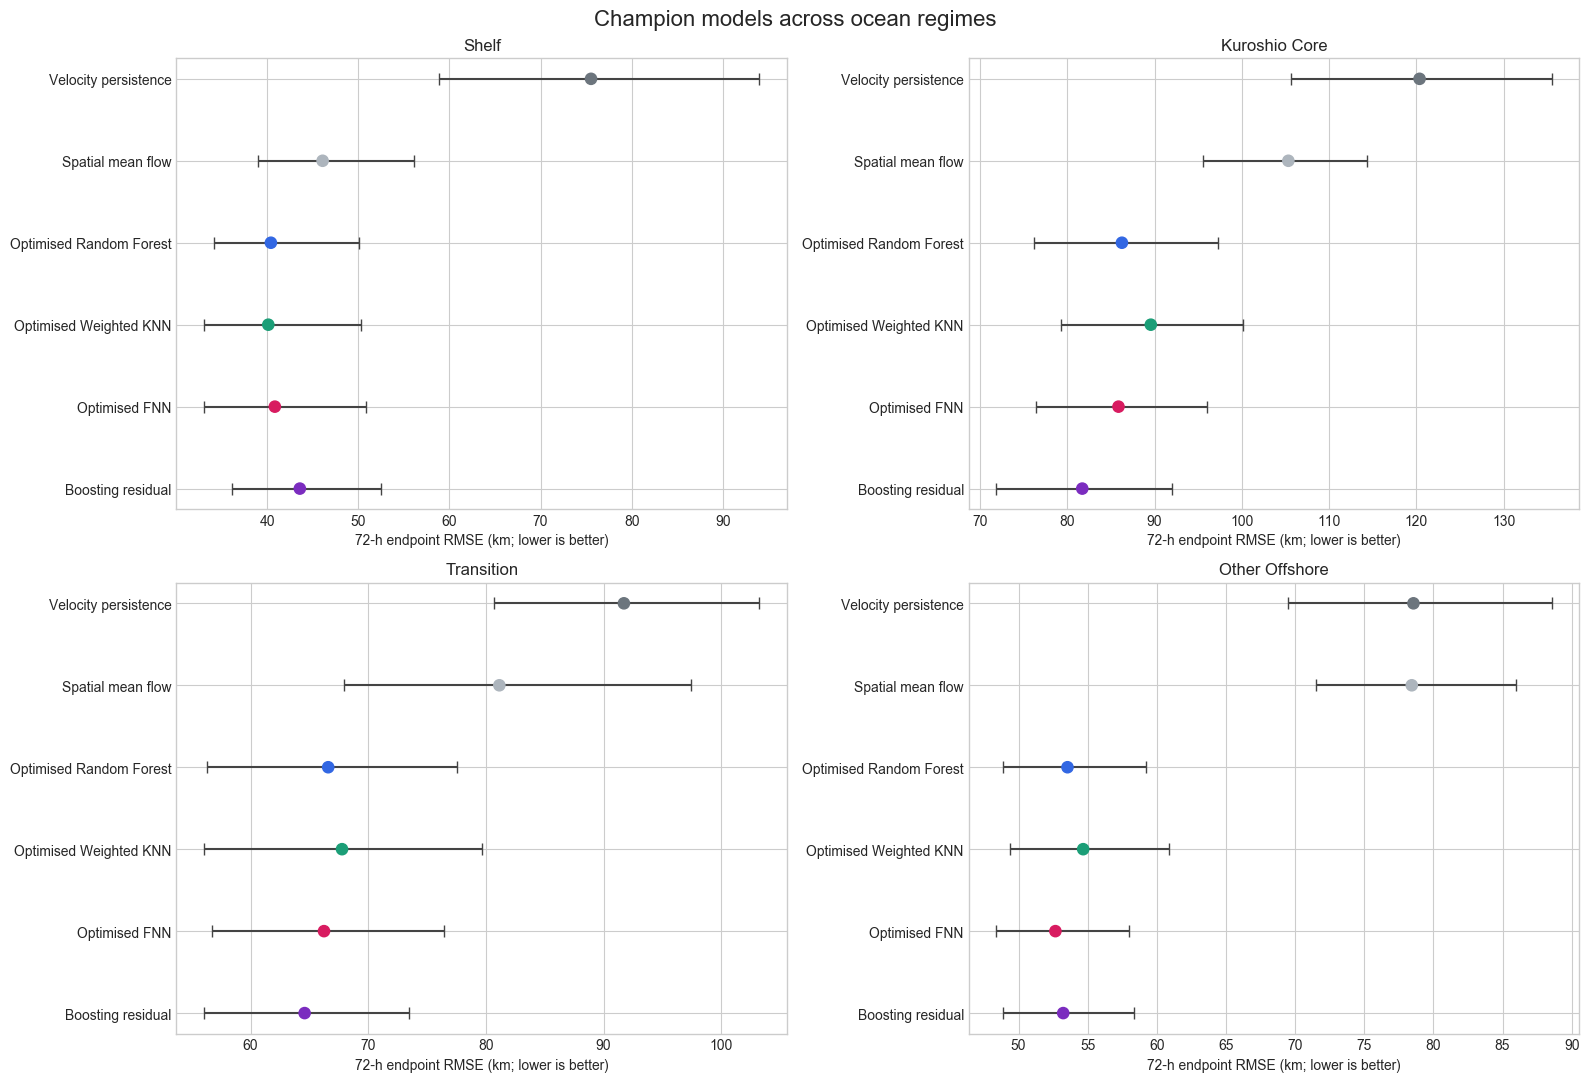

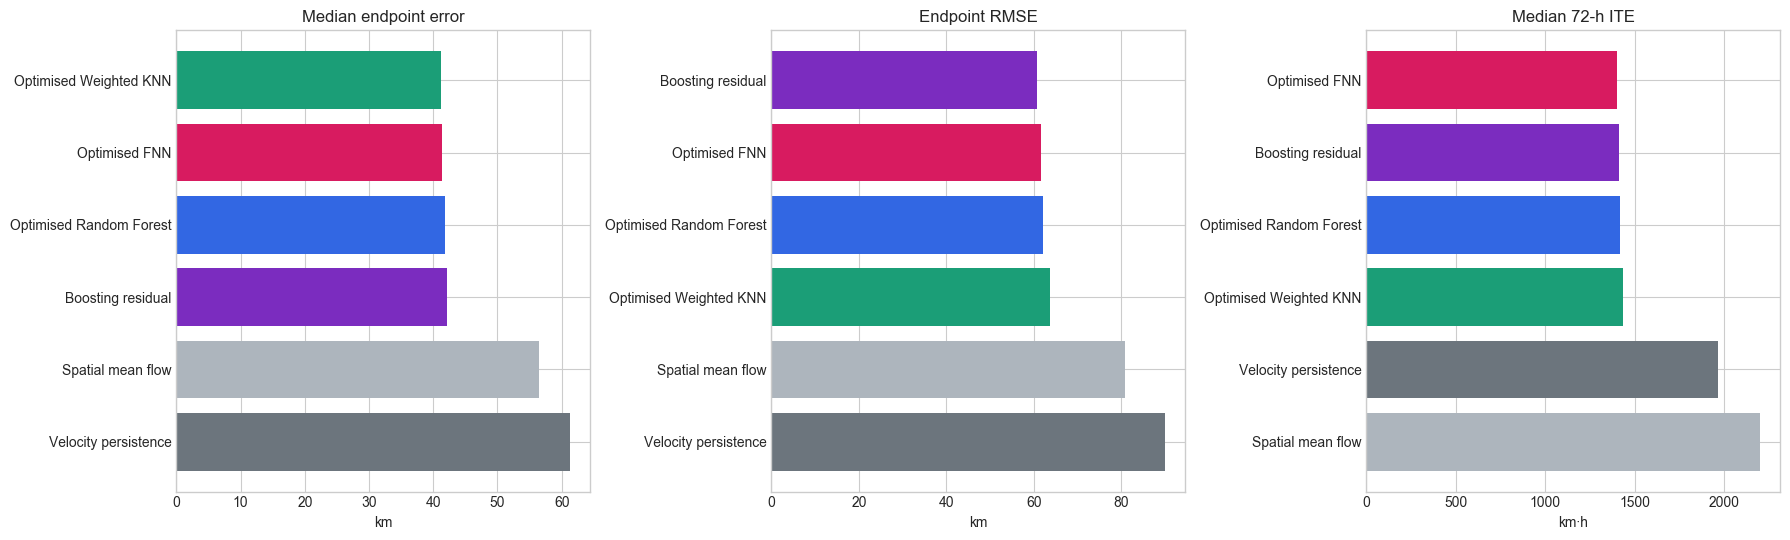

In [6]:
ORDER=['Velocity persistence','Spatial mean flow','Optimised Random Forest',
       'Optimised Weighted KNN','Optimised FNN','Boosting residual']
REGIMES=['Shelf','Kuroshio Core','Transition','Other Offshore']
COLORS={'Velocity persistence':'#6c757d','Spatial mean flow':'#adb5bd',
        'Optimised Random Forest':'#3267e3','Optimised Weighted KNN':'#1b9e77',
        'Optimised FNN':'#d81b60','Boosting residual':'#7b2cbf'}

fig,axes=plt.subplots(2,2,figsize=(16,11),sharex=False)
for ax,regime in zip(axes.flat,REGIMES):
    d=boot[(boot.regime==regime)&(boot.metric=='rmse_72h_km')].set_index('model').reindex(ORDER)
    y=np.arange(len(d)); x=d.estimate.to_numpy(); lo=d.ci_lower.to_numpy(); hi=d.ci_upper.to_numpy()
    ax.errorbar(x,y,xerr=np.vstack([x-lo,hi-x]),fmt='none',ecolor='#444',capsize=4,zorder=1)
    ax.scatter(x,y,c=[COLORS[m] for m in d.index],s=65,zorder=2)
    ax.set_yticks(y,d.index); ax.invert_yaxis(); ax.set_title(regime,fontweight='bold')
    ax.set_xlabel('72-h endpoint RMSE (km; lower is better)')
fig.suptitle('Champion models across ocean regimes',fontsize=16,fontweight='bold')
fig.tight_layout(); fig.savefig(OUT/'champion_rmse_by_regime.png',dpi=200,bbox_inches='tight'); plt.show()

fig,axes=plt.subplots(1,3,figsize=(18,5.5))
for ax,metric,title,unit in zip(axes,
    ['median_72h_km','rmse_72h_km','median_ite_km_h'],
    ['Median endpoint error','Endpoint RMSE','Median 72-h ITE'],['km','km','km·h']):
    overall=errors.groupby('model',observed=True).apply(
        lambda g: summarise(g)[metric],include_groups=False).reindex(ORDER).sort_values(ascending=False)
    ax.barh(overall.index,overall.values,color=[COLORS[m] for m in overall.index])
    ax.set_title(title,fontweight='bold'); ax.set_xlabel(unit)
fig.tight_layout(); fig.savefig(OUT/'champion_overall_metrics.png',dpi=200,bbox_inches='tight'); plt.show()

## 6. 自动生成结论

结论必须区分“绝对误差较大”和“模型相对baseline仍有skill”。Kuroshio误差大不自动代表模型没有价值；高速流动会把相似的相对误差放大成更大的公里数。

In [7]:
learned=['Optimised FNN','Boosting residual','Optimised Weighted KNN','Optimised Random Forest']
for regime in REGIMES:
    d=summary[summary.regime.eq(regime)].set_index('model')
    best_med=d.loc[learned,'median_72h_km'].idxmin()
    best_rmse=d.loc[learned,'rmse_72h_km'].idxmin()
    best_ite=d.loc[learned,'median_ite_km_h'].idxmin()
    baseline_rmse=d.loc[['Velocity persistence','Spatial mean flow'],'rmse_72h_km'].min()
    gain=100*(1-d.loc[best_rmse,'rmse_72h_km']/baseline_rmse)
    print(f'{regime}: median冠军={best_med}; RMSE冠军={best_rmse}; ITE冠军={best_ite}; '
          f'RMSE冠军相对最佳物理baseline改善{gain:.1f}%')

display(Markdown("""
### 解释边界

- 本Notebook可以完整回答72小时终点误差、ITE、尾部风险和区域bootstrap不确定性。
- 当前冠军CSV没有保存`case × lead_time`的完整误差矩阵，因此这里没有伪造1–72小时区域曲线。
- 若后续要画每个regime的逐小时曲线，应让四个冠军训练Notebook额外导出逐case逐小时预测或误差。
"""))

Shelf: median冠军=Optimised Weighted KNN; RMSE冠军=Optimised Weighted KNN; ITE冠军=Optimised Random Forest; RMSE冠军相对最佳物理baseline改善12.9%
Kuroshio Core: median冠军=Boosting residual; RMSE冠军=Boosting residual; ITE冠军=Boosting residual; RMSE冠军相对最佳物理baseline改善22.4%
Transition: median冠军=Optimised Weighted KNN; RMSE冠军=Boosting residual; ITE冠军=Optimised Random Forest; RMSE冠军相对最佳物理baseline改善20.4%
Other Offshore: median冠军=Optimised Weighted KNN; RMSE冠军=Optimised FNN; ITE冠军=Optimised Random Forest; RMSE冠军相对最佳物理baseline改善32.9%



### 解释边界

- 本Notebook可以完整回答72小时终点误差、ITE、尾部风险和区域bootstrap不确定性。
- 当前冠军CSV没有保存`case × lead_time`的完整误差矩阵，因此这里没有伪造1–72小时区域曲线。
- 若后续要画每个regime的逐小时曲线，应让四个冠军训练Notebook额外导出逐case逐小时预测或误差。
